Realizado por:
Andrea Bonilla
July Aparicio
Ioshua Castillejos

# Clasificación de Sentimientos de Reseñas de Películas en IMDb con Redes Neuronales Recurrentes
## A - Objetivo

Desarrollar un método basado en redes neuronales recurrentes que permita clasificar con precisión las reseñas de películas en IMDb en una de las dos
categorías: positiva o negativa

## B - Conjunto de datos

Los datos corresponden a un dataset de reseñas de películas en IMDb,
disponibles en el siguiente enlace. El dataset contiene miles de reseñas
etiquetadas con su correspondiente rating y etiqueta de sentimiento (positivo o
negativo)

## C - Actividades por realizar
1. Preprocesamiento de las reseñas: Construir un pipeline que permita limpiar y
tokenizar las reseñas de texto, convirtiéndolas en secuencias numéricas
utilizando embeddings
2. Desarrollo de la arquitectura de red neuronal recurrente: Implementar una
RNN (por ejemplo, LSTM o GRU) para la clasificación de las reseñas en dos
categorías. La arquitectura de la red es de libre elección, pero se sugiere incluir
capas de embedding, capas recurrentes y una capa densa de salida con
activación sigmoide. Justificar la elección de cada capa del modelo.
3. Entrenamiento y evaluación del modelo: Dividir el dataset en conjuntos de
entrenamiento, validación y prueba. Entrenar el modelo utilizando el conjunto de
entrenamiento y evaluar su rendimiento con el conjunto de prueba, reportando
métricas de precisión, recall y F1-score.

### 1. Librerías

In [26]:
# Librerías requeridas
# PyTorch para construir y entrenar las redes
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader, random_split

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler

from time import time
from gensim.models import Word2Vec
from nltk.stem import PorterStemmer
stemmer = PorterStemmer()

import copy

# Para descargar los recursos desde la red con proxy (error de certificado SSL)
try:
    import truststore
    truststore.inject_into_ssl()
except ImportError:
    pass

import nltk
from nltk.corpus import stopwords
from wordcloud import WordCloud

# Se descargan los recursos de NLTK si no están instalados
for recurso, ruta in [('punkt', 'tokenizers/punkt'),
                      ('punkt_tab', 'tokenizers/punkt_tab'),
                      ('stopwords', 'corpora/stopwords')]:
    try:
        nltk.data.find(ruta)
    except LookupError:
        nltk.download(recurso, quiet=True)

# Semillas
torch.manual_seed(42)
np.random.seed(42)

# Se usa GPU si está disponible
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Usando dispositivo: {device}')

Usando dispositivo: cuda


### 2. Importar los datos

In [27]:
GHI = pd.read_csv('movie.csv')
GHI.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    40000 non-null  object
 1   label   40000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 625.1+ KB


### 3. Exploración de datos

In [28]:
GHI.head()

,text,label
0,I grew up (b. 1965) watching and loving the Th...,0
1,"When I put this movie in my DVD player, and sa...",0
2,Why do people who do not know what a particula...,0
3,Even though I have great interest in Biblical ...,0
4,Im a die hard Dads Army fan and nothing will e...,1


In [29]:
GHI['label'].value_counts()

label
0    20019
1    19981
Name: count, dtype: int64

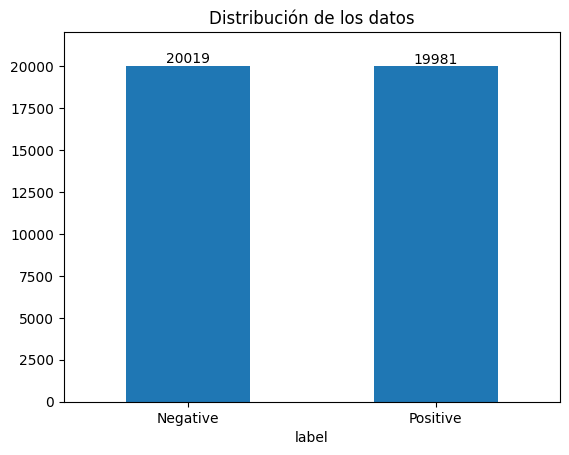

In [30]:
ax = GHI.groupby('label').count().plot(kind='bar', title='Distribución de los datos',
                                       legend=False)
ax.set_xticklabels(['Negative', 'Positive'], rotation=0)

for container in ax.containers:
    ax.bar_label(container)

ax.margins(y=0.1)  # espacio para las etiquetas


In [31]:
longitudes = GHI['text'].str.split().str.len()
print(f"Textos muy cortos (<5 palabras): {(longitudes < 5).sum()}")
print(f"Textos muy largos (>1000 palabras): {(longitudes > 1000).sum()}")
print(f"Filas con registros nulos: {GHI['text'].isnull().sum()}")
print(f"Filas invalidas: {GHI['text'].isna().sum()}")
print(f"Filas duplicadas: {GHI['text'].duplicated().sum()}")

Textos muy cortos (<5 palabras): 1
Textos muy largos (>1000 palabras): 60
Filas con registros nulos: 0
Filas invalidas: 0
Filas duplicadas: 277


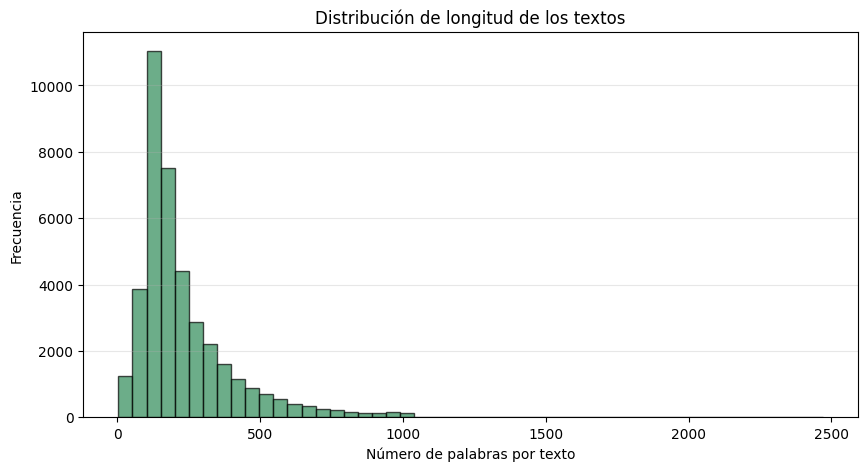

count    40000.000000
mean       231.339250
std        171.194123
min          4.000000
25%        126.000000
50%        173.000000
75%        282.000000
max       2470.000000
Name: text, dtype: float64


In [32]:
longitudes = GHI['text'].str.split().str.len()

plt.figure(figsize=(10,5))
plt.hist(longitudes, bins=50, color='seagreen', edgecolor='black', alpha=0.7)
plt.xlabel('Número de palabras por texto')
plt.ylabel('Frecuencia')
plt.title('Distribución de longitud de los textos')
plt.grid(axis='y', alpha=0.3)
plt.show()

print(longitudes.describe())

Hallazgos de la exploración de datos.

Las clases están casi balanceadas (20.019 negativas y 19.981 positivas), así que no hizo falta balancear. No hay nulos, pero hay 277 reseñas repetidas que se quitan antes de dividir. Las reseñas tienen en promedio 231 palabras y la mediana es 173. La más corta tiene 4 palabras y la más larga 2.470, por eso el histograma tiene una cola larga a la derecha. Solo una reseña tiene menos de 5 palabras y 60 pasan de 1.000.

### 4. Separación de datos

Antes de dividir se quitan las reseñas duplicadas, para que una misma reseña no termine en entrenamiento y en prueba al mismo tiempo. Quedan 39.723 registros. Se dividen en 70 % entrenamiento (27.806), 15 % validación (5.958) y 15 % prueba (5.959), estratificando por la etiqueta para mantener la proporción de clases. Se usa la semilla 42.

In [33]:
# Se quitan los duplicados antes de dividir
GHI = GHI.drop_duplicates(subset='text').reset_index(drop=True)
print(f"Registros tras eliminar duplicados: {len(GHI)}")

SEED = 42

# 70% train, 15% validación, 15% prueba
train_GHI, resto = train_test_split(GHI, test_size=0.30, stratify=GHI["label"], random_state=SEED)
val_GHI, test_GHI = train_test_split(resto, test_size=0.50, stratify=resto["label"], random_state=SEED)
print(f"Datos entrenamiento: {len(train_GHI)}\nDatos validacion: {len(val_GHI)} \nDatos prueba: {len(test_GHI)}")

Registros tras eliminar duplicados: 39723
Datos entrenamiento: 27806
Datos validacion: 5958 
Datos prueba: 5959


### 5. Función de limpieza de textos

La función `limpiar_texto` convierte entidades HTML como `&amp;`, quita etiquetas como `<br />` y las URLs y pasa el texto a minúsculas. Las negaciones contraídas se separan (por ejemplo *didn't* queda *did not*) y las demás contracciones, como *'s* o *'ll*, se borran. Después se dejan solo letras.

También se quitan las stopwords de NLTK y las palabras de una letra, pero se dejan *no*, *nor*, *not*, *but*, *very*, *too*, *against* y *only* porque cambian el sentido de la reseña. Por último se aplica el stemmer de Porter, que deja cada palabra en su raíz (*movies* queda *movi*). El resultado se guarda en la columna `palabras_limpias` de los tres conjuntos.

In [34]:
import re
import html

# Se conservan las negaciones y palabras que cambian el sentido
conservar = {'no', 'nor', 'not', 'but', 'very', 'too', 'against', 'only'}
stop_words = set(stopwords.words('english')) - conservar

def limpiar_texto(texto, quitar_stopwords=True):
    texto = html.unescape(texto)
    texto = re.sub(r'<[^>]+>', ' ', texto)  # html
    texto = re.sub(r'http\S+|www\.\S+', ' ', texto)  # urls
    texto = texto.lower().replace('\u2019', "'")  # minúsculas
    texto = re.sub(r"\bwon't\b", 'will not', texto)  # negaciones
    texto = re.sub(r"\bcan't\b", 'can not', texto)
    texto = re.sub(r"n't\b", ' not', texto)
    texto = re.sub(r"'(s|re|ve|d|ll|m)\b", ' ', texto)  # contracciones
    texto = re.sub(r'[^a-z\s]', ' ', texto)  # solo letras
    palabras_limpias = texto.split()
    if quitar_stopwords:
        palabras_limpias = [t for t in palabras_limpias if t not in stop_words and len(t) > 1]
        #palabras_limpias = [stemmer.stem(t) for t in palabras_limpias]
    # Retorna la lista de palabras limpias
    return palabras_limpias

print(limpiar_texto("I didn't like it.<br /><br />It WASN'T good &amp; I can't recommend it!!"))

# Limpieza de train, validación y prueba
for conjunto in (train_GHI, val_GHI, test_GHI):
    conjunto['palabras_limpias'] = conjunto['text'].apply(limpiar_texto)

['not', 'like', 'not', 'good', 'not', 'recommend']


### 6. Embeddings

Se entrena un Word2Vec con las reseñas de entrenamiento ya limpias, con vectores de 100 dimensiones, ventana de 5 y `min_count=1`. Por el stemming, las palabras más parecidas a *great* salen como raíces (*excel*, *fantast*, *amaz*).

In [35]:
from gensim.models import Word2Vec

EMB_DIM = 100

w2v = Word2Vec(
    sentences=train_GHI["palabras_limpias"].tolist(),
    vector_size=EMB_DIM,
    window=5,
    min_count=1,
    workers=4,
    seed=42,
)

print(f"Palabras en el modelo Word2Vec: {len(w2v.wv):,}")
print("Similares a 'great':", w2v.wv.most_similar('great', topn=5))

Palabras en el modelo Word2Vec: 78,514
Similares a 'great': [('excellent', 0.7718245983123779), ('fine', 0.7673653364181519), ('wonderful', 0.7671758532524109), ('fantastic', 0.7380691170692444), ('good', 0.6919610500335693)]


### 7. Matriz con embeddings

El vocabulario se arma solo con entrenamiento, para no usar información de validación ni de prueba. El índice 0 es el padding, el 1 las palabras desconocidas y los demás las 19.998 palabras más frecuentes, en total 20.000 índices. Cada reseña queda como una secuencia de 300 índices. Si es más corta se completa con ceros al inicio y si es más larga se corta y se deja el comienzo.

La matriz de embeddings tiene una fila por palabra del vocabulario con su vector de Word2Vec, y el padding queda en ceros. Las palabras sin vector tendrían valores aleatorios (normal con media 0 y desviación 0.1), pero como Word2Vec se entrenó con `min_count=1` todas tienen vector.

In [36]:
from collections import Counter

MAX_VOCAB = 20000
MAX_LEN = 300

# Vocabulario con los datos de train. 0 = padding, 1 = palabra desconocida
contador = Counter(t for toks in train_GHI["palabras_limpias"] for t in toks)
palabras = [p for p, _ in contador.most_common(MAX_VOCAB - 2)]
word2idx = {p: i + 2 for i, p in enumerate(palabras)}
VOCAB_SIZE = len(word2idx) + 2

def codificar(tokens):
    ids = [word2idx.get(t, 1) for t in tokens][:MAX_LEN]
    # padding al inicio
    return [0] * (MAX_LEN - len(ids)) + ids

In [37]:
# Matriz de embeddings con los vectores de Word2Vec
matriz_emb = np.random.normal(0, 0.1, (VOCAB_SIZE, EMB_DIM)).astype("float32")
matriz_emb[0] = 0.0  # padding
encontradas = 0
for palabra, idx in word2idx.items():
    if palabra in w2v.wv:
        matriz_emb[idx] = w2v.wv[palabra]
        encontradas += 1
print(f"Palabras con vector Word2Vec: {encontradas:,} / {len(word2idx):,}")


Palabras con vector Word2Vec: 19,998 / 19,998


### 8. Creación de tensores

Las secuencias se pasan a tensores, `X` con los índices de las palabras y `y` con la etiqueta (0 negativa, 1 positiva). Los lotes son de 128 en entrenamiento, mezclados en cada época, y de 256 en validación y prueba.

In [38]:
# Tensores: X con las palabras limpias codificadas
# y con las etiquetas (0 y 1)
def a_tensores(frame):
    X = torch.tensor([codificar(t) for t in frame["palabras_limpias"]], dtype=torch.long)
    y = torch.tensor(frame["label"].values, dtype=torch.float32)
    return X, y

X_train, y_train = a_tensores(train_GHI)
X_val, y_val = a_tensores(val_GHI)
X_test, y_test = a_tensores(test_GHI)

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=128, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=256)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=256)
print(X_train.shape, X_val.shape, X_test.shape)

torch.Size([27806, 300]) torch.Size([5958, 300]) torch.Size([5959, 300])


### 9. Modelo

La primera capa es un embedding de 100 dimensiones inicializado con los vectores de Word2Vec. Así la red no empieza desde cero y ya sabe qué palabras se parecen, como *great* y *excellent*. La capa se deja entrenable para que los vectores se ajusten a la clasificación de sentimiento. El índice 0 es el padding.

Después del embedding va un dropout de 0.3, porque con 20.000 palabras en el vocabulario el modelo puede memorizar palabras y no generalizar.

Luego hay dos capas LSTM de 128 unidades con dropout de 0.3 entre ellas. Se usó LSTM y no una RNN simple porque las reseñas son largas (se cortan en 300 palabras) y la RNN simple olvida lo del principio por el desvanecimiento del gradiente.

Encima de la LSTM se puso una capa de atención. Una capa lineal le asigna un puntaje a cada palabra, con softmax esos puntajes se vuelven pesos y se saca el promedio ponderado de las salidas de la LSTM. Con esto el modelo no se queda solo con el último estado y puede fijarse más en palabras como *awful* o *masterpiece*. Las posiciones de padding se enmascaran.

Ese vector pasa por otro dropout y por una capa densa de una neurona con sigmoide, que da la probabilidad de que la reseña sea positiva. Con 0.5 o más se toma como positiva. La pérdida es `BCELoss`.

Para entrenar se usa Adam con tasa de aprendizaje de 0.001 y weight decay de 1e-5, y se limita la norma del gradiente a 1.0 porque en las LSTM los gradientes a veces se disparan.

In [39]:
class SentimentLSTM(nn.Module):
    def __init__(self, vocab_size, emb_dim=100, hidden_dim=128, num_layers=2, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.emb_dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(emb_dim, hidden_dim, num_layers=num_layers,
                            batch_first=True, dropout=dropout if num_layers > 1 else 0)
        self.atencion = nn.Linear(hidden_dim, 1)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        mascara = (x != 0)
        emb = self.emb_dropout(self.embedding(x))
        salida, _ = self.lstm(emb)

        # atención (sin contar el padding)
        puntajes = self.atencion(salida).squeeze(-1)
        puntajes = puntajes.masked_fill(~mascara, -1e9)
        pesos = torch.softmax(puntajes, dim=1)
        h = (salida * pesos.unsqueeze(-1)).sum(dim=1)

        h = self.dropout(h)
        return self.sigmoid(self.fc(h)).squeeze(1)

modelo = SentimentLSTM(VOCAB_SIZE, EMB_DIM).to(device)
modelo.embedding.weight.data.copy_(torch.tensor(matriz_emb))
modelo.embedding.weight.requires_grad = True
criterio = nn.BCELoss()
optimizador = optim.Adam(modelo.parameters(), lr=1e-3, weight_decay=1e-5)  # regularización L2
# Se reduce el lr a la mitad si la pérdida de validación no baja
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizador, mode="min", factor=0.5, patience=1)

print(modelo)
print(f"Parámetros entrenables: {sum(p.numel() for p in modelo.parameters() if p.requires_grad):,}")

SentimentLSTM(
  (embedding): Embedding(20000, 100, padding_idx=0)
  (emb_dropout): Dropout(p=0.3, inplace=False)
  (lstm): LSTM(100, 128, num_layers=2, batch_first=True, dropout=0.3)
  (atencion): Linear(in_features=128, out_features=1, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)
Parámetros entrenables: 2,250,114


### 10. Entrenamiento con validación

En cada época el modelo se entrena con `train_loader` y se evalúa con `val_loader`. Se guarda el modelo con menor pérdida de validación y el entrenamiento para si no mejora en 10 épocas seguidas, con un máximo de 50. `ReduceLROnPlateau` baja la tasa de aprendizaje a la mitad cuando la pérdida de validación se estanca. El conjunto de prueba no se toca en esta parte.

In [40]:
def ejecutar_epoca(loader, entrenar):
    modelo.train() if entrenar else modelo.eval()
    perdida_total, aciertos, n = 0.0, 0, 0
    with torch.set_grad_enabled(entrenar):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            prob = modelo(xb)
            perdida = criterio(prob, yb)
            if entrenar:
                optimizador.zero_grad()
                perdida.backward()
                nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
                optimizador.step()
            perdida_total += perdida.item() * len(yb)
            aciertos += ((prob >= 0.5).float() == yb).sum().item()
            n += len(yb)
    return perdida_total / n, aciertos / n

EPOCAS = 50
PACIENCIA = 10

historial = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
mejor_val_loss = float("inf")
mejor_estado = None
sin_mejora = 0
inicio = time()

for epoca in range(1, EPOCAS + 1):
    tr_loss, tr_acc = ejecutar_epoca(train_loader, entrenar=True)
    va_loss, va_acc = ejecutar_epoca(val_loader, entrenar=False)
    scheduler.step(va_loss)
    for k, v in zip(historial, (tr_loss, va_loss, tr_acc, va_acc)):
        historial[k].append(v)
    print(f"Época {epoca:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f} | lr {optimizador.param_groups[0]['lr']:.1e}")

    if va_loss < mejor_val_loss:
        mejor_val_loss = va_loss
        mejor_estado = copy.deepcopy(modelo.state_dict())
        sin_mejora = 0
    else:
        sin_mejora += 1
        if sin_mejora >= PACIENCIA:
            print(f"Early stopping: la pérdida de validación no mejora hace {PACIENCIA} épocas")
            break

modelo.load_state_dict(mejor_estado)  # mejor modelo
print(f"Tiempo de entrenamiento: {time() - inicio:.1f} s | mejor val loss: {mejor_val_loss:.4f}")

Época  1 | train loss 0.3946 acc 0.8198 | val loss 0.3036 acc 0.8773 | lr 1.0e-03
Época  2 | train loss 0.2881 acc 0.8817 | val loss 0.2734 acc 0.8912 | lr 1.0e-03
Época  3 | train loss 0.2330 acc 0.9078 | val loss 0.2752 acc 0.8892 | lr 1.0e-03
Época  4 | train loss 0.1822 acc 0.9303 | val loss 0.2578 acc 0.8995 | lr 1.0e-03
Época  5 | train loss 0.1309 acc 0.9525 | val loss 0.2998 acc 0.8921 | lr 1.0e-03
Época  6 | train loss 0.0912 acc 0.9684 | val loss 0.3566 acc 0.8844 | lr 5.0e-04
Época  7 | train loss 0.0547 acc 0.9815 | val loss 0.4162 acc 0.8849 | lr 5.0e-04
Época  8 | train loss 0.0381 acc 0.9879 | val loss 0.4669 acc 0.8783 | lr 2.5e-04
Época  9 | train loss 0.0277 acc 0.9916 | val loss 0.5305 acc 0.8803 | lr 2.5e-04
Época 10 | train loss 0.0238 acc 0.9924 | val loss 0.5997 acc 0.8773 | lr 1.3e-04
Época 11 | train loss 0.0207 acc 0.9937 | val loss 0.5929 acc 0.8792 | lr 1.3e-04
Época 12 | train loss 0.0182 acc 0.9947 | val loss 0.6206 acc 0.8770 | lr 6.3e-05
Época 13 | train

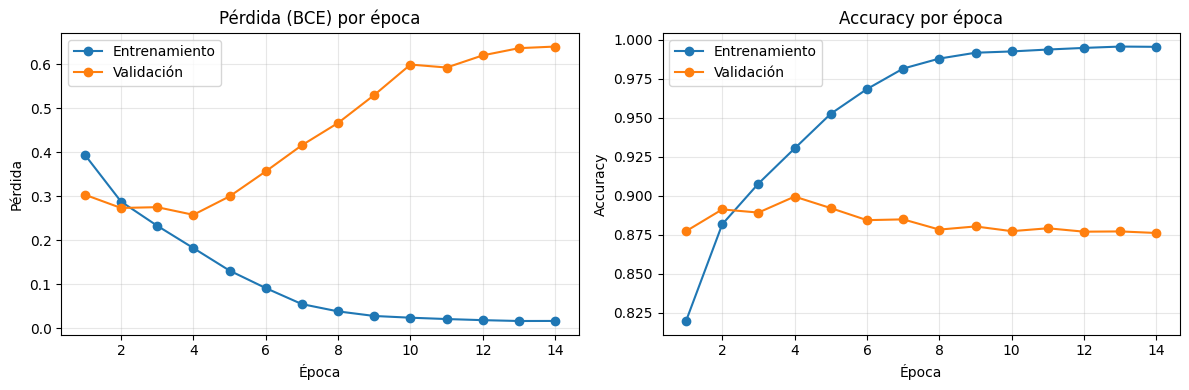

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epocas_x = range(1, len(historial["train_loss"]) + 1)

axes[0].plot(epocas_x, historial["train_loss"], marker="o", label="Entrenamiento")
axes[0].plot(epocas_x, historial["val_loss"], marker="o", label="Validación")
axes[0].set_title("Pérdida (BCE) por época")
axes[0].set_xlabel("Época"); axes[0].set_ylabel("Pérdida")

axes[1].plot(epocas_x, historial["train_acc"], marker="o", label="Entrenamiento")
axes[1].plot(epocas_x, historial["val_acc"], marker="o", label="Validación")
axes[1].set_title("Accuracy por época")
axes[1].set_xlabel("Época"); axes[1].set_ylabel("Accuracy")

for ax in axes:
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.show()

### 11. Evaluación en el conjunto de prueba

El mejor modelo se evalúa una sola vez con el 15 % de prueba, que no se usó para entrenar ni para escoger el modelo. Se reportan accuracy, precisión, recall y F1-score, y la matriz de confusión.

Accuracy : 0.8990
Precisión: 0.8865
Recall   : 0.9156
F1-score : 0.9008

              precision    recall  f1-score   support

    Negativa     0.9123    0.8823    0.8971      2973
    Positiva     0.8865    0.9156    0.9008      2986

    accuracy                         0.8990      5959
   macro avg     0.8994    0.8989    0.8989      5959
weighted avg     0.8994    0.8990    0.8989      5959



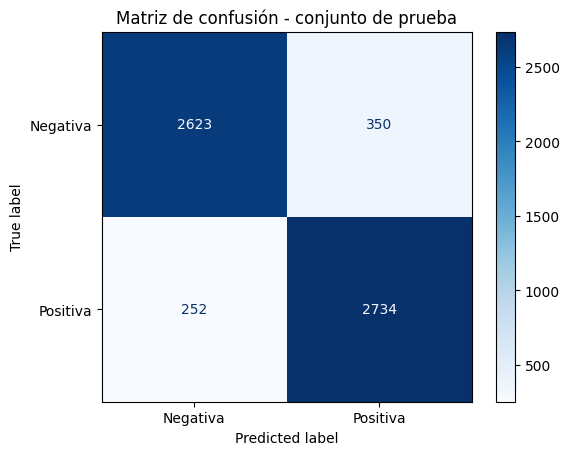

In [42]:
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score)

modelo.eval()
probs, reales = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        probs.append(modelo(xb.to(device)).cpu())
        reales.append(yb)
probs = torch.cat(probs).numpy()
y_real = torch.cat(reales).numpy().astype(int)
y_pred = (probs >= 0.5).astype(int)

print(f"Accuracy : {accuracy_score(y_real, y_pred):.4f}")
print(f"Precisión: {precision_score(y_real, y_pred):.4f}")
print(f"Recall   : {recall_score(y_real, y_pred):.4f}")
print(f"F1-score : {f1_score(y_real, y_pred):.4f}\n")
print(classification_report(y_real, y_pred, target_names=["Negativa", "Positiva"], digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_real, y_pred),
                       display_labels=["Negativa", "Positiva"]).plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - conjunto de prueba")
plt.show()

### 12. Pérdida en test, AUC y accuracy por longitud (Word2Vec)

Se calcula la pérdida en prueba, para ver si se parece a la de validación, y el AUC con su curva ROC. También se mira el accuracy por rangos de longitud de la reseña. La idea es ver si el modelo se equivoca más en las reseñas cortas o en las de más de 300 tokens, que se cortan.

Pérdida test: 0.2708 | mejor pérdida validación: 0.2578
AUC test: 0.9595
         reseñas  accuracy
rango                     
0-50         632    0.9177
51-100      2628    0.8912
101-200     1798    0.9010
201-300      555    0.9045
>300         346    0.9046


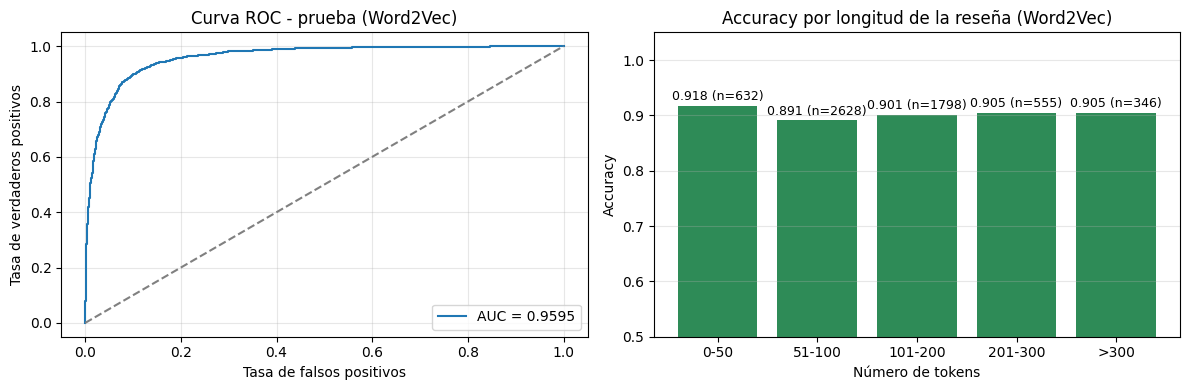

In [43]:
from sklearn.metrics import roc_auc_score, roc_curve

test_loss_w2v = criterio(torch.tensor(probs), torch.tensor(y_real, dtype=torch.float32)).item()
auc = roc_auc_score(y_real, probs)
print(f"Pérdida test: {test_loss_w2v:.4f} | mejor pérdida validación: {mejor_val_loss:.4f}")
print(f"AUC test: {auc:.4f}")

# test_loader no tiene shuffle, el orden es el mismo de test_GHI
resultados = pd.DataFrame({
    "n_tokens": test_GHI["palabras_limpias"].str.len().values,
    "real": y_real,
    "pred": y_pred,
    "prob": probs,
})
resultados["acierto"] = (resultados["real"] == resultados["pred"]).astype(int)

cortes = [0, 50, 100, 200, 300, np.inf]
etiquetas = ["0-50", "51-100", "101-200", "201-300", ">300"]
resultados["rango"] = pd.cut(resultados["n_tokens"], bins=cortes, labels=etiquetas)
por_longitud = resultados.groupby("rango", observed=False).agg(reseñas=("acierto", "size"),
                                                                       accuracy=("acierto", "mean"))
print(por_longitud.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

fpr, tpr, _ = roc_curve(y_real, probs)
axes[0].plot(fpr, tpr, label=f"AUC = {auc:.4f}")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_title("Curva ROC - prueba (Word2Vec)")
axes[0].set_xlabel("Tasa de falsos positivos")
axes[0].set_ylabel("Tasa de verdaderos positivos")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].bar(etiquetas, por_longitud["accuracy"], color="seagreen")
for i, (acc, n) in enumerate(zip(por_longitud["accuracy"], por_longitud["reseñas"])):
    axes[1].text(i, acc + 0.01, f"{acc:.3f} (n={n})", ha="center", fontsize=9)
axes[1].set_ylim(0.5, 1.05)
axes[1].set_title("Accuracy por longitud de la reseña (Word2Vec)")
axes[1].set_xlabel("Número de tokens")
axes[1].set_ylabel("Accuracy")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 13. Ejemplos de errores (Word2Vec)

Se revisan los errores en los que el modelo estaba más seguro: las reseñas negativas con mayor probabilidad de ser positivas (falsos positivos) y las positivas con menor probabilidad (falsos negativos). Se muestran 5 de cada uno.

In [44]:
resultados["texto"] = test_GHI["text"].str.replace("<br />", " ").values

fp = resultados[(resultados["real"] == 0) & (resultados["pred"] == 1)]
fn = resultados[(resultados["real"] == 1) & (resultados["pred"] == 0)]
print("Falsos positivos:", len(fp))
print("Falsos negativos:", len(fn))

print("----- Falsos positivos (negativas que el modelo dio como positivas) -----")
for _, fila in fp.sort_values("prob", ascending=False).head(5).iterrows():
    print(f"Probabilidad: {fila['prob']:.3f} | Tokens: {fila['n_tokens']}")
    print(fila["texto"][:500])

print("----- Falsos negativos (positivas que el modelo dio como negativas) -----")
for _, fila in fn.sort_values("prob").head(5).iterrows():
    print(f"Probabilidad: {fila['prob']:.3f} | Tokens: {fila['n_tokens']}")
    print(fila["texto"][:500])

Falsos positivos: 350
Falsos negativos: 252
----- Falsos positivos (negativas que el modelo dio como positivas) -----
Probabilidad: 1.000 | Tokens: 26
this is a great movie. I love the series on tv and so I loved the movie. One of the best things in the movie is that Helga finally admits her deepest darkest secret to Arnold!!! that was great. i loved it it was pretty funny too. It's a great movie! Doy!!!
Probabilidad: 0.999 | Tokens: 70
The latest Rumor going around is that Vh1 is starting casting calls for I Love New York 3 mid 2008. So does this mean Budah or Tailor made dumped New York or does this mean New York dumped the winner?  I know Flavor of Love is coming up to it's 3rd season, so now with a Flavor of Love 3 and a I love New York 3.....will there ever be a true winner???  I've also heard a few rumors that Chance WILL be brought back for the 3rd Season of I Love New York!!!! I have also heard rumors that New York will
Probabilidad: 0.999 | Tokens: 28
The opening credits are p

## Modelo con embeddings GloVe 300d (comparación con Word2Vec 100d)

Para comparar se entrena otro modelo con los vectores preentrenados de GloVe. Se usan los mismos conjuntos y el mismo vocabulario, y las variables de esta parte terminan en `_glove`.

### 14. Embeddings GloVe

Se usan los vectores de GloVe de 300 dimensiones. Si `glove.6B.300d.txt` está en la carpeta se carga de ahí y si no se descarga con gensim (`glove-wiki-gigaword-300`). La matriz de embeddings sigue el orden del vocabulario. Las palabras que no están en GloVe reciben un vector aleatorio con la misma desviación estándar de GloVe y el padding queda en ceros. Como las palabras pasaron por stemming, muchas no aparecen en GloVe, y eso puede afectar a este modelo.

In [45]:
import os
from gensim.models import KeyedVectors
import gensim.downloader as api

EMB_DIM_GLOVE = 300

if os.path.exists("glove.6B.300d.txt"):
    glove = KeyedVectors.load_word2vec_format("glove.6B.300d.txt", binary=False, no_header=True)
else:
    glove = api.load("glove-wiki-gigaword-300")

print(glove.most_similar("great", topn=5))
print(glove.most_similar("terrible", topn=5))

encontradas_glove = [p for p in word2idx if p in glove]
desv = np.std([glove[p] for p in encontradas_glove])
rng = np.random.default_rng(SEED)

emb_matrix_glove = rng.normal(scale=desv, size=(MAX_VOCAB, EMB_DIM_GLOVE)).astype(np.float32)
emb_matrix_glove[0] = 0
for palabra in encontradas_glove:
    emb_matrix_glove[word2idx[palabra]] = glove[palabra]
print(f"Palabras con vector de GloVe: {len(encontradas_glove):,} de {len(word2idx):,}")

del glove

[('greatest', 0.6583032608032227), ('good', 0.6410046815872192), ('tremendous', 0.6299972534179688), ('well', 0.5856286883354187), ('especially', 0.5592252612113953)]
[('horrible', 0.8621524572372437), ('awful', 0.7882837653160095), ('dreadful', 0.7239290475845337), ('horrendous', 0.6983873844146729), ('horrific', 0.6624177098274231)]
Palabras con vector de GloVe: 19,890 de 19,998


### 15. Secuencias y tensores (GloVe)

Las secuencias son de 300 palabras, igual que con Word2Vec, con ceros al inicio en las cortas y dejando el comienzo en las largas. Los lotes son de 128 en entrenamiento y de 256 en validación y prueba.

In [46]:
MAX_LEN_GLOVE = 300

def codificar_glove(tokens):
    ids = [word2idx.get(t, 1) for t in tokens][:MAX_LEN_GLOVE]   # se deja el inicio de la reseña
    return [0] * (MAX_LEN_GLOVE - len(ids)) + ids

def a_tensores_glove(df):
    X = torch.tensor([codificar_glove(t) for t in df["palabras_limpias"]], dtype=torch.long)
    y = torch.tensor(df["label"].values, dtype=torch.float32)
    return X, y

X_train_glove, y_train_glove = a_tensores_glove(train_GHI)
X_val_glove, y_val_glove = a_tensores_glove(val_GHI)
X_test_glove, y_test_glove = a_tensores_glove(test_GHI)

train_loader_glove = DataLoader(TensorDataset(X_train_glove, y_train_glove), batch_size=128, shuffle=True)
val_loader_glove = DataLoader(TensorDataset(X_val_glove, y_val_glove), batch_size=256)
test_loader_glove = DataLoader(TensorDataset(X_test_glove, y_test_glove), batch_size=256)
print(X_train_glove.shape, X_val_glove.shape, X_test_glove.shape)

torch.Size([27806, 300]) torch.Size([5958, 300]) torch.Size([5959, 300])


### 16. Modelo GloVe

Se usa la misma clase `SentimentLSTM` del modelo con Word2Vec. Solo cambia el embedding, que en este caso es de 300 dimensiones y se inicializa con la matriz de GloVe. El resto se mantiene: dropout de 0.3, dos capas LSTM de 128 unidades, atención y la neurona de salida con sigmoide. El entrenamiento también es igual, con `BCELoss`, Adam (lr = 0.001, weight decay = 1e-5), `ReduceLROnPlateau` y recorte del gradiente a 1.0.

In [47]:
# misma clase SentimentLSTM del modelo con Word2Vec
torch.manual_seed(SEED)
modelo_glove = SentimentLSTM(emb_matrix_glove.shape[0], EMB_DIM_GLOVE).to(device)
modelo_glove.embedding.weight.data.copy_(torch.tensor(emb_matrix_glove))
modelo_glove.embedding.weight.requires_grad = True
criterio_glove = nn.BCELoss()
optimizador_glove = optim.Adam(modelo_glove.parameters(), lr=1e-3, weight_decay=1e-5)  # regularización L2
# Se reduce el lr a la mitad si la pérdida de validación no baja
scheduler_glove = optim.lr_scheduler.ReduceLROnPlateau(optimizador_glove, mode="min", factor=0.5, patience=1)

print(modelo_glove)
print(f"Parámetros entrenables: {sum(p.numel() for p in modelo_glove.parameters() if p.requires_grad):,}")

SentimentLSTM(
  (embedding): Embedding(20000, 300, padding_idx=0)
  (emb_dropout): Dropout(p=0.3, inplace=False)
  (lstm): LSTM(300, 128, num_layers=2, batch_first=True, dropout=0.3)
  (atencion): Linear(in_features=128, out_features=1, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)
Parámetros entrenables: 6,352,514


### 17. Entrenamiento con validación (GloVe)

Se entrena igual que el modelo con Word2Vec. Se guarda el modelo con menor pérdida de validación, con early stopping de paciencia 10, máximo 50 épocas y `ReduceLROnPlateau`. Al final se cargan los mejores pesos y se grafican las curvas.

In [48]:
def ejecutar_epoca_glove(loader, entrenar):
    modelo_glove.train() if entrenar else modelo_glove.eval()
    perdida_total, aciertos, n = 0.0, 0, 0
    with torch.set_grad_enabled(entrenar):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            prob = modelo_glove(xb)
            perdida = criterio_glove(prob, yb)
            if entrenar:
                optimizador_glove.zero_grad()
                perdida.backward()
                nn.utils.clip_grad_norm_(modelo_glove.parameters(), 1.0)
                optimizador_glove.step()
            perdida_total += perdida.item() * len(yb)
            aciertos += ((prob >= 0.5).float() == yb).sum().item()
            n += len(yb)
    return perdida_total / n, aciertos / n

EPOCAS_GLOVE = 50
PACIENCIA_GLOVE = 10

historial_glove = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
mejor_val_loss_glove = float("inf")
mejor_estado_glove = None
sin_mejora = 0
inicio = time()

for epoca in range(1, EPOCAS_GLOVE + 1):
    tr_loss, tr_acc = ejecutar_epoca_glove(train_loader_glove, entrenar=True)
    va_loss, va_acc = ejecutar_epoca_glove(val_loader_glove, entrenar=False)
    scheduler_glove.step(va_loss)
    for k, v in zip(historial_glove, (tr_loss, va_loss, tr_acc, va_acc)):
        historial_glove[k].append(v)
    print(f"Época {epoca:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f} | lr {optimizador_glove.param_groups[0]['lr']:.1e}")

    if va_loss < mejor_val_loss_glove:
        mejor_val_loss_glove = va_loss
        mejor_estado_glove = copy.deepcopy(modelo_glove.state_dict())
        sin_mejora = 0
    else:
        sin_mejora += 1
        if sin_mejora >= PACIENCIA_GLOVE:
            print(f"Early stopping: la pérdida de validación no mejora hace {PACIENCIA_GLOVE} épocas")
            break

modelo_glove.load_state_dict(mejor_estado_glove)  # mejor modelo
print(f"Tiempo de entrenamiento: {time() - inicio:.1f} s | mejor val loss: {mejor_val_loss_glove:.4f}")

Época  1 | train loss 0.3834 acc 0.8235 | val loss 0.2829 acc 0.8810 | lr 1.0e-03
Época  2 | train loss 0.2329 acc 0.9092 | val loss 0.2557 acc 0.8966 | lr 1.0e-03
Época  3 | train loss 0.1718 acc 0.9372 | val loss 0.2946 acc 0.8874 | lr 1.0e-03
Época  4 | train loss 0.1176 acc 0.9589 | val loss 0.3204 acc 0.8855 | lr 5.0e-04
Época  5 | train loss 0.0613 acc 0.9817 | val loss 0.3940 acc 0.8830 | lr 5.0e-04
Época  6 | train loss 0.0406 acc 0.9886 | val loss 0.4619 acc 0.8818 | lr 2.5e-04
Época  7 | train loss 0.0274 acc 0.9931 | val loss 0.5010 acc 0.8815 | lr 2.5e-04
Época  8 | train loss 0.0192 acc 0.9950 | val loss 0.5583 acc 0.8812 | lr 1.3e-04
Época  9 | train loss 0.0164 acc 0.9964 | val loss 0.5634 acc 0.8828 | lr 1.3e-04
Época 10 | train loss 0.0144 acc 0.9965 | val loss 0.5962 acc 0.8813 | lr 6.3e-05
Época 11 | train loss 0.0136 acc 0.9970 | val loss 0.5996 acc 0.8802 | lr 6.3e-05
Época 12 | train loss 0.0124 acc 0.9973 | val loss 0.5972 acc 0.8815 | lr 3.1e-05
Early stopping: 

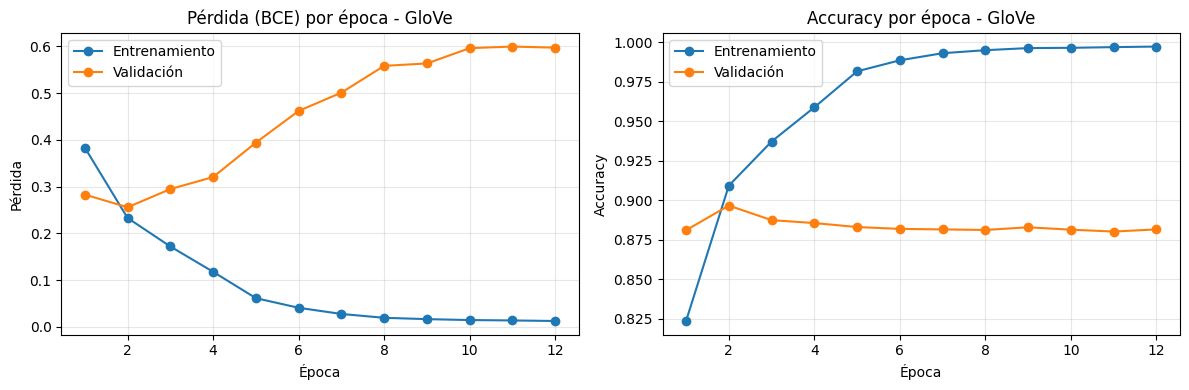

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epocas_x = range(1, len(historial_glove["train_loss"]) + 1)

axes[0].plot(epocas_x, historial_glove["train_loss"], marker="o", label="Entrenamiento")
axes[0].plot(epocas_x, historial_glove["val_loss"], marker="o", label="Validación")
axes[0].set_title("Pérdida (BCE) por época - GloVe")
axes[0].set_xlabel("Época"); axes[0].set_ylabel("Pérdida")

axes[1].plot(epocas_x, historial_glove["train_acc"], marker="o", label="Entrenamiento")
axes[1].plot(epocas_x, historial_glove["val_acc"], marker="o", label="Validación")
axes[1].set_title("Accuracy por época - GloVe")
axes[1].set_xlabel("Época"); axes[1].set_ylabel("Accuracy")

for ax in axes:
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.show()

### 18. Evaluación en el conjunto de prueba (GloVe)

El mejor modelo de GloVe se evalúa con el mismo conjunto de prueba que se usó para Word2Vec.

Accuracy : 0.8911
Precisión: 0.8957
Recall   : 0.8858
F1-score : 0.8907
AUC      : 0.9582
Pérdida test: 0.2649 | mejor pérdida validación: 0.2557

              precision    recall  f1-score   support

    Negativa     0.8866    0.8964    0.8915      2973
    Positiva     0.8957    0.8858    0.8907      2986

    accuracy                         0.8911      5959
   macro avg     0.8911    0.8911    0.8911      5959
weighted avg     0.8911    0.8911    0.8911      5959



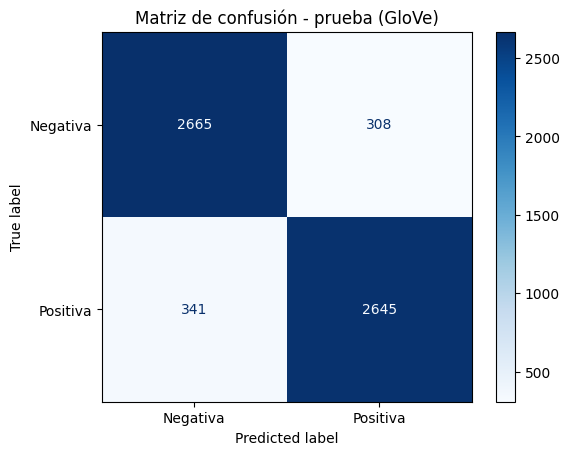

In [50]:
from sklearn.metrics import roc_auc_score, roc_curve

modelo_glove.eval()
probs_glove, reales_glove = [], []
with torch.no_grad():
    for xb, yb in test_loader_glove:
        probs_glove.append(modelo_glove(xb.to(device)).cpu())
        reales_glove.append(yb)
probs_glove = torch.cat(probs_glove).numpy()
y_real_glove = torch.cat(reales_glove).numpy().astype(int)
y_pred_glove = (probs_glove >= 0.5).astype(int)

test_loss_glove = criterio_glove(torch.tensor(probs_glove), torch.tensor(y_real_glove, dtype=torch.float32)).item()
auc_glove = roc_auc_score(y_real_glove, probs_glove)

print(f"Accuracy : {accuracy_score(y_real_glove, y_pred_glove):.4f}")
print(f"Precisión: {precision_score(y_real_glove, y_pred_glove):.4f}")
print(f"Recall   : {recall_score(y_real_glove, y_pred_glove):.4f}")
print(f"F1-score : {f1_score(y_real_glove, y_pred_glove):.4f}")
print(f"AUC      : {auc_glove:.4f}")
print(f"Pérdida test: {test_loss_glove:.4f} | mejor pérdida validación: {mejor_val_loss_glove:.4f}\n")
print(classification_report(y_real_glove, y_pred_glove, target_names=["Negativa", "Positiva"], digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_real_glove, y_pred_glove),
                       display_labels=["Negativa", "Positiva"]).plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - prueba (GloVe)")
plt.show()

### 19. Pérdida en test, AUC y accuracy por longitud (GloVe)

Se repite el análisis por longitud que se hizo con Word2Vec, para ver si los dos modelos fallan en el mismo tipo de reseñas. La pérdida en test y el AUC ya se calcularon en la evaluación, así que aquí se grafican la curva ROC y el accuracy por rango de longitud.

         reseñas  accuracy
rango                     
0-50         632    0.9114
51-100      2628    0.8824
101-200     1798    0.8932
201-300      555    0.9063
>300         346    0.8844


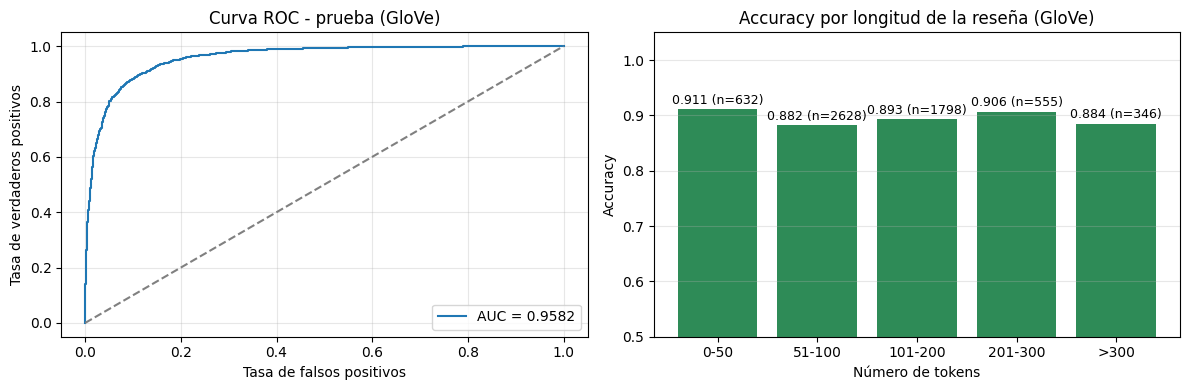

In [51]:
# test_loader_glove no tiene shuffle, el orden es el mismo de test_GHI
resultados_glove = pd.DataFrame({
    "n_tokens": test_GHI["palabras_limpias"].str.len().values,
    "real": y_real_glove,
    "pred": y_pred_glove,
    "prob": probs_glove,
})
resultados_glove["acierto"] = (resultados_glove["real"] == resultados_glove["pred"]).astype(int)

cortes = [0, 50, 100, 200, 300, np.inf]
etiquetas = ["0-50", "51-100", "101-200", "201-300", ">300"]
resultados_glove["rango"] = pd.cut(resultados_glove["n_tokens"], bins=cortes, labels=etiquetas)
por_longitud_glove = resultados_glove.groupby("rango", observed=False).agg(reseñas=("acierto", "size"),
                                                                       accuracy=("acierto", "mean"))
print(por_longitud_glove.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

fpr, tpr, _ = roc_curve(y_real_glove, probs_glove)
axes[0].plot(fpr, tpr, label=f"AUC = {auc_glove:.4f}")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_title("Curva ROC - prueba (GloVe)")
axes[0].set_xlabel("Tasa de falsos positivos")
axes[0].set_ylabel("Tasa de verdaderos positivos")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].bar(etiquetas, por_longitud_glove["accuracy"], color="seagreen")
for i, (acc, n) in enumerate(zip(por_longitud_glove["accuracy"], por_longitud_glove["reseñas"])):
    axes[1].text(i, acc + 0.01, f"{acc:.3f} (n={n})", ha="center", fontsize=9)
axes[1].set_ylim(0.5, 1.05)
axes[1].set_title("Accuracy por longitud de la reseña (GloVe)")
axes[1].set_xlabel("Número de tokens")
axes[1].set_ylabel("Accuracy")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 20. Ejemplos de errores (GloVe)

Igual que con Word2Vec, se muestran los 5 falsos positivos y los 5 falsos negativos en los que el modelo estaba más seguro. Sirve para ver si los dos modelos se equivocan en reseñas parecidas.

In [52]:
resultados_glove["texto"] = test_GHI["text"].str.replace("<br />", " ").values

fp_glove = resultados_glove[(resultados_glove["real"] == 0) & (resultados_glove["pred"] == 1)]
fn_glove = resultados_glove[(resultados_glove["real"] == 1) & (resultados_glove["pred"] == 0)]
print("Falsos positivos:", len(fp_glove))
print("Falsos negativos:", len(fn_glove))

print("----- Falsos positivos (negativas que el modelo dio como positivas) -----")
for _, fila in fp_glove.sort_values("prob", ascending=False).head(5).iterrows():
    print(f"Probabilidad: {fila['prob']:.3f} | Tokens: {fila['n_tokens']}")
    print(fila["texto"][:500])

print("----- Falsos negativos (positivas que el modelo dio como negativas) -----")
for _, fila in fn_glove.sort_values("prob").head(5).iterrows():
    print(f"Probabilidad: {fila['prob']:.3f} | Tokens: {fila['n_tokens']}")
    print(fila["texto"][:500])

Falsos positivos: 308
Falsos negativos: 341
----- Falsos positivos (negativas que el modelo dio como positivas) -----
Probabilidad: 0.999 | Tokens: 26
this is a great movie. I love the series on tv and so I loved the movie. One of the best things in the movie is that Helga finally admits her deepest darkest secret to Arnold!!! that was great. i loved it it was pretty funny too. It's a great movie! Doy!!!
Probabilidad: 0.994 | Tokens: 23
This is, without a doubt, the most hilarious movie I've ever seen. Seriously, if the makers of this movie are ever discovered, they'll put guys like Jim Carrey out of a job. Rent "Jack-O" tonight! Believe me, you won't regret it!
Probabilidad: 0.993 | Tokens: 89
I saw this when it was in the theater, it started out so strong I mean back in 1980 this was a bold movie and the special effects were excellent AT THE time. Now you would have to of been at least 30 or so in 1980 to really understand this point because studying film historically misses the mind

### 21. Comparación Word2Vec 100d vs. GloVe 300d

Se comparan las métricas de prueba y las curvas ROC de los dos modelos. Los dos usan `BCELoss`, así que la pérdida en test también se puede comparar. Como la arquitectura, el largo de las secuencias, la pérdida y el early stopping son los mismos, la diferencia está en el embedding. Word2Vec tiene 100 dimensiones y se entrenó con las mismas reseñas, mientras que GloVe es preentrenado y tiene 300 dimensiones.

                                         Accuracy  Precisión  Recall  \
Word2Vec 100d (LSTM 2 capas + atención)    0.8990     0.8865  0.9156   
GloVe 300d (LSTM 2 capas + atención)       0.8911     0.8957  0.8858   

                                         F1-score     AUC  Pérdida test  \
Word2Vec 100d (LSTM 2 capas + atención)    0.9008  0.9595        0.2708   
GloVe 300d (LSTM 2 capas + atención)       0.8907  0.9582        0.2649   

                                         Épocas  
Word2Vec 100d (LSTM 2 capas + atención)    14.0  
GloVe 300d (LSTM 2 capas + atención)       12.0  


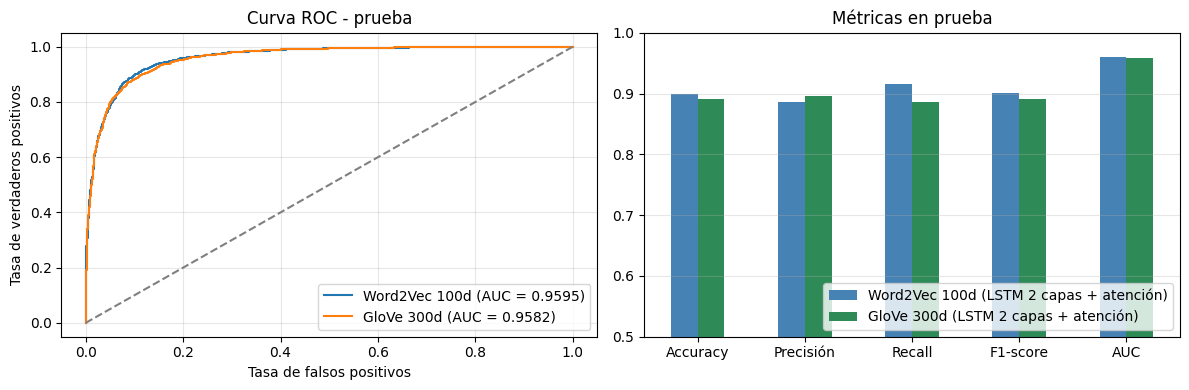

In [53]:
def metricas(y_true, y_hat, prob, perdida, historial_modelo):
    return {
        "Accuracy": accuracy_score(y_true, y_hat),
        "Precisión": precision_score(y_true, y_hat),
        "Recall": recall_score(y_true, y_hat),
        "F1-score": f1_score(y_true, y_hat),
        "AUC": roc_auc_score(y_true, prob),
        "Pérdida test": perdida,
        "Épocas": len(historial_modelo["train_loss"]),
    }

comparacion = pd.DataFrame({
    "Word2Vec 100d (LSTM 2 capas + atención)": metricas(y_real, y_pred, probs, test_loss_w2v, historial),
    "GloVe 300d (LSTM 2 capas + atención)": metricas(y_real_glove, y_pred_glove, probs_glove, test_loss_glove, historial_glove),
}).T
print(comparacion.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for nombre, y_t, p in [("Word2Vec 100d", y_real, probs), ("GloVe 300d", y_real_glove, probs_glove)]:
    fpr, tpr, _ = roc_curve(y_t, p)
    axes[0].plot(fpr, tpr, label=f"{nombre} (AUC = {roc_auc_score(y_t, p):.4f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_title("Curva ROC - prueba")
axes[0].set_xlabel("Tasa de falsos positivos")
axes[0].set_ylabel("Tasa de verdaderos positivos")
axes[0].legend(); axes[0].grid(alpha=0.3)

cols = ["Accuracy", "Precisión", "Recall", "F1-score", "AUC"]
comparacion[cols].T.plot(kind="bar", ax=axes[1], rot=0, color=["steelblue", "seagreen"])
axes[1].set_ylim(0.5, 1.0)
axes[1].set_title("Métricas en prueba")
axes[1].grid(axis="y", alpha=0.3)
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()